<h1><center id="title">DataLab Cup 3: Reverse Image Caption</center></h1>
<center id="author">Shan-Hung Wu &amp; DataLab<br/>Fall 2026</center>

<h1><center class="subtitle">Text to Image</center></h1>
<h2 id="Platform:-Kaggle">Platform: <a href="https://www.kaggle.com/competitions/2026-datalab-cup-3-reverse-image-caption/overview">Kaggle</a></h2><h2 id="Overview">Overview</h2><p>In this work, we are interested in translating text in the form of single-sentence human-written descriptions directly into image pixels. For example, "<strong>this flower has petals that are yellow and has a ruffled stamen</strong>" and "<strong>this pink and yellow flower has a beautiful yellow center with many stamens</strong>". You have to develop a novel deep architecture and GAN formulation to effectively translate visual concepts from characters to pixels.</p>
<p>More specifically, given a set of texts, your task is to generate reasonable images with size 64x64x3 to illustrate the corresponding texts. Here we use <a href="http://www.robots.ox.ac.uk/~vgg/data/flowers/102/">Oxford-102 flower dataset</a> and its <a href="https://drive.google.com/file/d/0B0ywwgffWnLLcms2WWJQRFNSWXM/view">paired texts</a> as our training dataset.</p>
<img alt="No description has been provided for this image" src="./data/example.png"/>
<ul>
<li>7370 images as training set, where each images is annotated with at most 10 texts.</li>
<li>819 texts for testing. You must generate 1 64x64x3 image for each text.</li>
</ul>

<h2 id="Conditional-GAN">Conditional GAN</h2><p>Given a text, in order to generate the image which can illustrate it, our model must meet several requirements:</p>
<ol>
<li>Our model should have ability to understand and extract the meaning of given texts.<ul>
<li>Use RNN or other language model, such as BERT, ELMo or XLNet, to capture the meaning of text.</li>
</ul>
</li>
<li>Our model should be able to generate image.<ul>
<li>Use GAN to generate high quality image.</li>
</ul>
</li>
<li>GAN-generated image should illustrate the text.<ul>
<li>Use conditional-GAN to generate image conditioned on given text.</li>
</ul>
</li>
</ol>
<p>Generative adversarial nets can be extended to a conditional model if both the generator and discriminator are conditioned on some extra information $y$. We can perform the conditioning by feeding $y$ into both the discriminator and generator as additional input layer.</p>
<img alt="No description has been provided for this image" src="./data/cGAN.png" width="500"/>
<p>There are two motivations for using some extra information in a GAN model:</p>
<ol>
<li>Improve GAN.</li>
<li>Generate targeted image.</li>
</ol>
<p>Additional information that is correlated with the input images, such as class labels, can be used to improve the GAN. This improvement may come in the form of more stable training, faster training, and/or generated images that have better quality.</p>
<img alt="No description has been provided for this image" src="./data/GANCLS.jpg"/>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import os
import string
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from PIL import Image
import random
import time
from pathlib import Path

import re
from IPython import display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

SAMPLE_DIR = Path('sample')
INFERENCE_DIR = Path('inference')


Using device: cuda


<h2 id="Preprocess-Text">Preprocess Text</h2><p>Since dealing with raw string is inefficient, we have done some data preprocessing for you:</p>
<ul>
<li>Delete text over <code>MAX_SEQ_LENGTH (20)</code>.</li>
<li>Delete all puntuation in the texts.</li>
<li>Encode each vocabulary in <code>dictionary/vocab.npy</code>.</li>
<li>Represent texts by a sequence of integer IDs.</li>
<li>Replace rare words by <code>&lt;RARE&gt;</code> token to reduce vocabulary size for more efficient training.</li>
<li>Add padding as <code>&lt;PAD&gt;</code> to each text to make sure all of them have equal length to <code>MAX_SEQ_LENGTH (20)</code>.</li>
</ul>
<p>It is worth knowing that there is no necessary to append <code>&lt;ST&gt;</code> and <code>&lt;ED&gt;</code> to each text because we don't need to generate any sequence in this task.</p>
<p>To make sure correctness of encoding of the original text, we can decode sequence vocabulary IDs by looking up the vocabulary dictionary:</p>
<ul>
<li><code>dictionary/word2Id.npy</code> is a numpy array mapping word to id.</li>
<li><code>dictionary/id2Word.npy</code> is a numpy array mapping id back to word.</li>
</ul>

In [2]:
dictionary_path = './dictionary'
vocab = np.load(dictionary_path + '/vocab.npy')
print('there are {} vocabularies in total'.format(len(vocab)))

word2Id_dict = {word: int(idx) for word, idx in np.load(dictionary_path + '/word2Id.npy') }
id2word_dict = dict(np.load(dictionary_path + '/id2Word.npy'))
print('Word to id mapping, for example: %s -> %s' % ('flower', word2Id_dict['flower']))
print('Id to word mapping, for example: %s -> %s' % ('1', id2word_dict['1']))
print('Tokens: <PAD>: %s; <RARE>: %s' % (word2Id_dict['<PAD>'], word2Id_dict['<RARE>']))

there are 5427 vocabularies in total
Word to id mapping, for example: flower -> 1
Id to word mapping, for example: 1 -> flower
Tokens: <PAD>: 5427; <RARE>: 5428


In [3]:
def sent2IdList(line, MAX_SEQ_LENGTH=20):
    MAX_SEQ_LIMIT = MAX_SEQ_LENGTH
    padding = 0

    # data preprocessing, remove all punctuation in the texts
    prep_line = re.sub('[%s]' % re.escape(string.punctuation), ' ', line.rstrip())
    prep_line = prep_line.replace('-', ' ')
    prep_line = prep_line.replace('-', ' ')
    prep_line = prep_line.replace('  ', ' ')
    prep_line = prep_line.replace('.', '')
    tokens = prep_line.split(' ')
    tokens = [
        tokens[i] for i in range(len(tokens))
        if tokens[i] != ' ' and tokens[i] != ''
    ]
    tokens = tokens[:MAX_SEQ_LIMIT]
    l = len(tokens)
    padding = MAX_SEQ_LIMIT - l

    # make sure length of each text is equal to MAX_SEQ_LENGTH, and replace the less common word with <RARE> token
    for i in range(padding):
        tokens.append('<PAD>')
    line = [
        word2Id_dict[tokens[k]]
        if tokens[k] in word2Id_dict else word2Id_dict['<RARE>']
        for k in range(len(tokens))
    ]

    return line


text = "the flower shown has yellow anther red pistil and bright red petals."
print(text)
print(sent2IdList(text))

the flower shown has yellow anther red pistil and bright red petals.
[9, 1, 82, 5, 11, 70, 20, 31, 3, 29, 20, 2, 5427, 5427, 5427, 5427, 5427, 5427, 5427, 5427]


<h2 id="Dataset">Dataset</h2><p>For training, the following files are in dataset folder:</p>
<ul>
<li><code>./dataset/text2ImgData.pkl</code> is a pandas dataframe with attribute 'Captions' and 'ImagePath'.<ul>
<li>'Captions' : A list of text id list contain 1 to 10 captions.</li>
<li>'ImagePath': Image path that store paired image.</li>
</ul>
</li>
<li><code>./102flowers/</code> is the directory containing all training images.</li>
<li><code>./dataset/testData.pkl</code> is a pandas a dataframe with attribute 'ID' and 'Captions', which contains testing data.</li>
</ul>

In [4]:
data_path = 'dataset'
df = pd.read_pickle(data_path + '/text2ImgData.pkl')
num_training_sample = len(df)
n_images_train = num_training_sample
print('There are %d image in training data' % (n_images_train))

There are 7370 image in training data


In [5]:
df.head(5)

,Captions,ImagePath
ID,,
6734,"[[9, 2, 17, 9, 1, 6, 14, 13, 18, 3, 41, 8, 11,...",./102flowers/image_06734.jpg
6736,"[[4, 1, 5, 12, 2, 3, 11, 31, 28, 68, 106, 132,...",./102flowers/image_06736.jpg
6737,"[[9, 2, 27, 4, 1, 6, 14, 7, 12, 19, 5427, 5427...",./102flowers/image_06737.jpg
6738,"[[9, 1, 5, 8, 54, 16, 38, 7, 12, 116, 325, 3, ...",./102flowers/image_06738.jpg
6739,"[[4, 12, 1, 5, 29, 11, 19, 7, 26, 70, 5427, 54...",./102flowers/image_06739.jpg


<h2 id="Create-Dataset-with-torch.utils.data">Create Dataset with torch.utils.data</h2>

In [6]:
# in this competition, you have to generate image in size 64x64x3
IMAGE_HEIGHT = 64
IMAGE_WIDTH = 64
IMAGE_CHANNEL = 3

In [7]:
class FlowerCaptionDataset(Dataset):
    def __init__(self, pickle_path):
        self.df = pd.read_pickle(pickle_path)
        self.captions = self.df['Captions'].values
        self.image_paths = self.df['ImagePath'].values

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # each image has 1 to 10 corresponding captions;
        # we choose one of them randomly for training
        caption = random.choice(self.captions[idx])
        caption = torch.from_numpy(np.asarray(caption, dtype=np.int64))

        image_path = Path(str(self.image_paths[idx]).replace('\\', '/'))
        if not image_path.is_absolute():
            image_path = image_path
        with Image.open(image_path) as image:
            img = torch.from_numpy(np.array(image.convert('RGB'))).permute(2, 0, 1).float() / 255.0
        img = F.interpolate(img.unsqueeze(0), size=(IMAGE_HEIGHT, IMAGE_WIDTH),
                            mode='bilinear', align_corners=False)[0]

        return img, caption


def dataset_generator(filenames, batch_size):
    ds = FlowerCaptionDataset(filenames)
    return DataLoader(ds, batch_size=batch_size, shuffle=True, drop_last=True,
                       num_workers=0, pin_memory=torch.cuda.is_available())

In [8]:
BATCH_SIZE = 64
dataset = dataset_generator(data_path + '/text2ImgData.pkl', BATCH_SIZE)

<h2 id="Conditional-GAN-Model">Conditional GAN Model</h2><p>As mentioned above, there are three models in this task, text encoder, generator and discriminator.</p>
<h2 id="Text-Encoder">Text Encoder</h2><p>A RNN encoder that captures the meaning of input text.</p>
<ul>
<li>Input: text, which is a list of ids.</li>
<li>Output: embedding, or hidden representation of input text.</li>
</ul>

In [9]:
class TextEncoder(nn.Module):
    """
    Encode text (a caption) into hidden representation
    input: text, which is a list of ids
    output: embedding, or hidden representation of input text in dimension of RNN_HIDDEN_SIZE
    """
    def __init__(self, hparas):
        super().__init__()
        self.hparas = hparas
        self.batch_size = self.hparas['BATCH_SIZE']

        # embedding, PyTorch's own API
        self.embedding = nn.Embedding(self.hparas['VOCAB_SIZE'], self.hparas['EMBED_DIM'])
        # RNN, here we use GRU cell, another common RNN cell similar to LSTM
        self.gru = nn.GRU(self.hparas['EMBED_DIM'], self.hparas['RNN_HIDDEN_SIZE'],
                           batch_first=True)

    def forward(self, text, hidden):
        text = self.embedding(text)
        output, state = self.gru(text, hidden.unsqueeze(0))
        return output[:, -1, :], state.squeeze(0)

    def initialize_hidden_state(self):
        return torch.zeros(self.hparas['BATCH_SIZE'], self.hparas['RNN_HIDDEN_SIZE'], device=device)

<h2 id="Generator">Generator</h2><p>A image generator which generates the target image illustrating the input text.</p>
<ul>
<li>Input: hidden representation of input text and random noise z with random seed.</li>
<li>Output: target image, which is conditioned on the given text, in size 64x64x3.</li>
</ul>

In [10]:
class Generator(nn.Module):
    """
    Generate fake image based on given text (hidden representation) and noise z
    input: text and noise
    output: fake image with size 64*64*3
    """
    def __init__(self, hparas):
        super().__init__()
        self.hparas = hparas
        self.flatten = nn.Flatten()
        self.d1 = nn.Linear(hparas['RNN_HIDDEN_SIZE'], hparas['DENSE_DIM'])
        self.d2 = nn.Linear(hparas['Z_DIM'] + hparas['DENSE_DIM'], 64 * 64 * 3)

    def forward(self, text, noise_z):
        text = self.flatten(text)
        text = self.d1(text)
        text = F.leaky_relu(text, negative_slope=0.2)

        # concatenate input text and random noise
        text_concat = torch.cat([noise_z, text], dim=1)
        text_concat = self.d2(text_concat)

        logits = text_concat.reshape(-1, 64, 64, 3).permute(0, 3, 1, 2).contiguous()
        output = torch.tanh(logits)

        return logits, output

<h2 id="Discriminator">Discriminator</h2><p>A binary classifier which can discriminate the real and fake image:</p>
<ol>
<li>Real image<ul>
<li>Input: real image and the paired text</li>
<li>Output: a floating number representing the result, which is expected to be 1.</li>
</ul>
</li>
<li>Fake Image<ul>
<li>Input: generated image and paired text</li>
<li>Output: a floating number representing the result, which is expected to be 0.</li>
</ul>
</li>
</ol>

In [11]:
class Discriminator(nn.Module):
    """
    Differentiate the real and fake image
    input: image and corresponding text
    output: labels, the real image should be 1, while the fake should be 0
    """
    def __init__(self, hparas):
        super().__init__()
        self.hparas = hparas
        self.flatten = nn.Flatten()
        self.d_text = nn.Linear(hparas['RNN_HIDDEN_SIZE'], hparas['DENSE_DIM'])
        self.d_img = nn.Linear(3 * 64 * 64, hparas['DENSE_DIM'])
        self.d = nn.Linear(hparas['DENSE_DIM'] * 2, 1)

    def forward(self, img, text):
        text = self.flatten(text)
        text = self.d_text(text)
        text = F.leaky_relu(text, negative_slope=0.2)

        # Match the original NHWC flatten order before the Dense layer.
        img = self.flatten(img.permute(0, 2, 3, 1).contiguous())
        img = self.d_img(img)
        img = F.leaky_relu(img, negative_slope=0.2)

        # concatenate image with paired text
        img_text = torch.cat([text, img], dim=1)

        logits = self.d(img_text)
        output = torch.sigmoid(logits)

        return logits, output

In [12]:
hparas = {
    'MAX_SEQ_LENGTH': 20,                     # maximum sequence length
    'EMBED_DIM': 256,                         # word embedding dimension
    'VOCAB_SIZE': max(word2Id_dict.values()) + 1,          # size of dictionary of captions
    'RNN_HIDDEN_SIZE': 128,                   # number of RNN neurons
    'Z_DIM': 512,                             # random noise z dimension
    'DENSE_DIM': 128,                         # number of neurons in dense layer
    'IMAGE_SIZE': [3, 64, 64],                # render image size (channels-first)
    'BATCH_SIZE': 64,
    'LR': 1e-4,
    'LR_DECAY': 0.5,
    'BETA_1': 0.5,
    'N_EPOCH': 10,                            # number of epoch for demo
    'N_SAMPLE': num_training_sample,          # size of training data
    'CHECKPOINTS_DIR': './checkpoints/demo',  # checkpoint path
    'PRINT_FREQ': 1                           # printing frequency of loss
}

In [13]:
text_encoder = TextEncoder(hparas).to(device)
generator = Generator(hparas).to(device)
discriminator = Discriminator(hparas).to(device)

<h2 id="Loss-Function-and-Optimization">Loss Function and Optimization</h2><p>Although the conditional GAN model is quite complex, the loss function used to optimize the network is relatively simple. Actually, it is simply a binary classification task, thus we use cross entropy as our loss.</p>

In [14]:
# This gives us the same cross-entropy-on-logits loss as
cross_entropy = nn.BCEWithLogitsLoss()

In [15]:
def discriminator_loss(real_logits, fake_logits):
    # output value of real image should be 1
    real_loss = cross_entropy(real_logits, torch.ones_like(real_logits))
    # output value of fake image should be 0
    fake_loss = cross_entropy(fake_logits, torch.zeros_like(fake_logits))
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_logits):
    # output value of fake image should be 1 (fool the discriminator)
    return cross_entropy(fake_logits, torch.ones_like(fake_logits))

In [16]:
# we use separate optimizers for training generator and discriminator
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=hparas['LR'], eps=1e-7)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=hparas['LR'], eps=1e-7)

In [17]:
# one benefit of a single dict checkpoint is we can still save everything
checkpoint_dir = hparas['CHECKPOINTS_DIR']
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, 'ckpt.pt')

In [18]:
def train_step(real_image, caption, hidden):
    # random noise for generator
    noise = torch.randn(real_image.shape[0], hparas['Z_DIM'], device=device)

    # The reference optimizes only G and D; avoid an unused encoder graph.
    with torch.no_grad():
        text_embed, hidden = text_encoder(caption, hidden[:caption.shape[0]])
    _, fake_image = generator(text_embed, noise)
    real_logits, real_output = discriminator(real_image, text_embed)
    fake_logits, fake_output = discriminator(fake_image, text_embed)

    g_loss = generator_loss(fake_logits)
    d_loss = discriminator_loss(real_logits, fake_logits)

    generator_params = list(generator.parameters())
    discriminator_params = list(discriminator.parameters())
    grad_g = torch.autograd.grad(g_loss, generator_params, retain_graph=True)
    grad_d = torch.autograd.grad(d_loss, discriminator_params)

    for p, g in zip(generator_params, grad_g):
        p.grad = g
    for p, g in zip(discriminator_params, grad_d):
        p.grad = g

    generator_optimizer.step()
    discriminator_optimizer.step()
    generator_optimizer.zero_grad()
    discriminator_optimizer.zero_grad()

    return g_loss.item(), d_loss.item()

In [19]:
@torch.no_grad()
def test_step(caption, noise, hidden):
    text_embed, hidden = text_encoder(caption, hidden)
    _, fake_image = generator(text_embed, noise)
    return fake_image

<h2 id="Visualiation">Visualiztion</h2><p>During training, we can visualize the generated image to evaluate the quality of generator. The followings are some functions helping visualization.</p>

In [ ]:
def merge(images, size):
    # images: (N, H, W, 3) numpy array
    h, w = images.shape[1], images.shape[2]
    img = np.zeros((h * size[0], w * size[1], 3))
    for idx, image in enumerate(images):
        i = idx % size[1]
        j = idx // size[1]
        img[j*h:j*h+h, i*w:i*w+w, :] = image
    return img

def imsave(images, size, path):
    # getting the pixel values between [0, 1] to save it
    return plt.imsave(path, merge(images, size) * 0.5 + 0.5)

def save_images(images, size, image_path):
    images = images.permute(0, 2, 3, 1).detach().cpu().numpy()
    return imsave(images, size, image_path)

In [21]:
def sample_generator(caption, batch_size):
    caption = torch.from_numpy(np.asarray(caption, dtype=np.int64))
    return DataLoader(caption, batch_size=batch_size)

<p>We always use same random seed and same senteces during training, which is more convenient for us to evaluate the quality of generated image.</p>

In [22]:
ni = int(np.ceil(np.sqrt(hparas['BATCH_SIZE'])))
sample_size = hparas['BATCH_SIZE']
sample_seed = torch.from_numpy(
    np.random.normal(loc=0.0, scale=1.0, size=(sample_size, hparas['Z_DIM'])).astype(np.float32)
).to(device)
sample_sentence = ["the flower shown has yellow anther red pistil and bright red petals."] * int(sample_size/ni) + \
                  ["this flower has petals that are yellow, white and purple and has dark lines"] * int(sample_size/ni) + \
                  ["the petals on this flower are white with a yellow center"] * int(sample_size/ni) + \
                  ["this flower has a lot of small round pink petals."] * int(sample_size/ni) + \
                  ["this flower is orange in color, and has petals that are ruffled and rounded."] * int(sample_size/ni) + \
                  ["the flower has yellow petals and the center of it is brown."] * int(sample_size/ni) + \
                  ["this flower has petals that are blue and white."] * int(sample_size/ni) +\
                  ["these white flowers have petals that start off white in color and end in a white towards the tips."] * int(sample_size/ni)

for i, sent in enumerate(sample_sentence):
    sample_sentence[i] = sent2IdList(sent)
sample_sentence = sample_generator(sample_sentence, hparas['BATCH_SIZE'])

<h2 id="Training">Training</h2>

In [23]:
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

In [24]:
def train(dataset, epochs):
    # hidden state of RNN
    hidden = text_encoder.initialize_hidden_state()
    steps_per_epoch = len(dataset)
    if steps_per_epoch == 0:
        raise ValueError('Training dataset has no complete batches.')

    for epoch in range(epochs):
        g_total_loss = 0
        d_total_loss = 0
        start = time.time()

        for image, caption in dataset:
            image, caption = image.to(device), caption.to(device)
            g_loss, d_loss = train_step(image, caption, hidden)
            g_total_loss += g_loss
            d_total_loss += d_loss

        time_tuple = time.localtime()
        time_string = time.strftime("%m/%d/%Y, %H:%M:%S", time_tuple)

        print("Epoch {}, gen_loss: {:.4f}, disc_loss: {:.4f}".format(
            epoch + 1, g_total_loss / steps_per_epoch, d_total_loss / steps_per_epoch))
        print('Time for epoch {} is {:.4f} sec'.format(epoch + 1, time.time() - start))

        # save the model
        if (epoch + 1) % 50 == 0 or epoch + 1 == epochs:
            torch.save({
                'text_encoder': text_encoder.state_dict(),
                'generator': generator.state_dict(),
                'discriminator': discriminator.state_dict(),
                'generator_optimizer': generator_optimizer.state_dict(),
                'discriminator_optimizer': discriminator_optimizer.state_dict(),
            }, checkpoint_path)

        # visualization
        if (epoch + 1) % hparas['PRINT_FREQ'] == 0:
            for caption in sample_sentence:
                fake_image = test_step(caption.to(device), sample_seed, hidden)
            save_images(fake_image, [ni, ni], SAMPLE_DIR / 'train_{:02d}.jpg'.format(epoch))

In [25]:
train(dataset, hparas['N_EPOCH'])

Epoch 1, gen_loss: 1.1207, disc_loss: 0.4962
Time for epoch 1 is 39.7895 sec
Epoch 2, gen_loss: 2.4716, disc_loss: 0.2982
Time for epoch 2 is 41.0901 sec
Epoch 3, gen_loss: 3.1949, disc_loss: 0.1345
Time for epoch 3 is 36.8468 sec
Epoch 4, gen_loss: 2.4406, disc_loss: 0.4461
Time for epoch 4 is 38.2580 sec
Epoch 5, gen_loss: 2.5763, disc_loss: 0.6437
Time for epoch 5 is 37.5282 sec
Epoch 6, gen_loss: 4.5457, disc_loss: 0.1513
Time for epoch 6 is 36.6090 sec
Epoch 7, gen_loss: 4.0710, disc_loss: 0.1083
Time for epoch 7 is 51.4317 sec
Epoch 8, gen_loss: 4.0128, disc_loss: 0.0708
Time for epoch 8 is 39.8526 sec
Epoch 9, gen_loss: 3.2811, disc_loss: 0.1381
Time for epoch 9 is 41.6832 sec
Epoch 10, gen_loss: 2.2558, disc_loss: 0.3730
Time for epoch 10 is 40.0496 sec


<h1><center class="subtitle">Evaluation</center></h1>
<p><code>dataset/testData.pkl</code> is a pandas dataframe containing testing text with attributes 'ID' and 'Captions'.</p>
<ul>
<li>'ID': text ID used to name generated image.</li>
<li>'Captions': text used as condition to generate image.</li>
</ul>
<p>For each captions, you need to generate <strong>inference_ID.png</strong> to evaluate quality of generated image. You must name the generated image in this format, otherwise we cannot evaluate your images.</p>

<h2 id="Testing-Dataset">Testing Dataset</h2><p>If you change anything during preprocessing of training dataset, you must make sure same operations have be done in testing dataset.</p>

In [26]:
class TestCaptionDataset(Dataset):
    def __init__(self, pickle_path):
        data = pd.read_pickle(pickle_path)
        self.captions = np.asarray(list(data['Captions'].values), dtype=np.int64)
        self.index = np.asarray(data['ID'].values)

    def __len__(self):
        return len(self.captions)

    def __getitem__(self, idx):
        return torch.tensor(self.captions[idx], dtype=torch.long), int(self.index[idx])


def testing_dataset_generator(batch_size):
    ds = TestCaptionDataset('dataset/testData.pkl')
    return DataLoader(ds, batch_size=batch_size, drop_last=False)

In [27]:
testing_dataset = testing_dataset_generator(hparas['BATCH_SIZE'])

In [28]:
data = pd.read_pickle('dataset/testData.pkl')
captions = data['Captions'].values

NUM_TEST = len(captions)
EPOCH_TEST = int(NUM_TEST / hparas['BATCH_SIZE'])

<h2 id="Inferece">Inferece</h2>

In [29]:
INFERENCE_DIR.mkdir(parents=True, exist_ok=True)


In [30]:
@torch.no_grad()
def inference(dataset):
    hidden = text_encoder.initialize_hidden_state()
    sample_size = hparas['BATCH_SIZE']
    sample_seed = torch.from_numpy(
        np.random.normal(loc=0.0, scale=1.0, size=(sample_size, hparas['Z_DIM'])).astype(np.float32)
    ).to(device)

    step = 0
    start = time.time()
    for captions, idx in dataset:
        captions = captions.to(device)
        fake_image = test_step(captions, sample_seed[:captions.shape[0]], hidden[:captions.shape[0]])
        fake_image = fake_image.permute(0, 2, 3, 1).cpu().numpy()  # (B, H, W, 3)
        step += 1
        for i in range(captions.shape[0]):
            plt.imsave(INFERENCE_DIR / 'inference_{:04d}.jpg'.format(int(idx[i])),
                       fake_image[i] * 0.5 + 0.5)

    print('Time for inference is {:.4f} sec'.format(time.time() - start))

In [31]:
checkpoint = torch.load(checkpoint_path, map_location=device)
text_encoder.load_state_dict(checkpoint['text_encoder'])
generator.load_state_dict(checkpoint['generator'])
discriminator.load_state_dict(checkpoint['discriminator'])
generator_optimizer.load_state_dict(checkpoint['generator_optimizer'])
discriminator_optimizer.load_state_dict(checkpoint['discriminator_optimizer'])

In [32]:
inference(testing_dataset)

Time for inference is 1.4170 sec


<h2 id="Inception-Score-&amp;-Cosine-Similarity">Inception Score &amp; Cosine Similarity</h2><p>In this competition, we use both <a href="https://arxiv.org/pdf/1606.03498.pdf">inception score</a> and cosine distance as our final score to evaluate quality and diversity of generated images. You can find more details about inception score in <a href="https://medium.com/octavian-ai/a-simple-explanation-of-the-inception-score-372dff6a8c7a">this article</a>. The final score is based on:</p>
<ul>
<li>Similarity of images and the given contents. How similar are the generated images and the given texts?</li>
<li>KL divergence of generated images. Are the generated images very diverse?</li>
</ul>
<p>After generating images with given testing texts, you have to run evaluation script to generate <code>score.csv</code> file, and then upload it to Kaggle to get the final score.</p>
<h3 id="1.-Run-evaluation-script-to-generate-score.csv">1. Run evaluation script to generate score.csv</h3><ol>
<li>Open terminal and move to the folder containing <code>inception_score.py</code>. Otherwise you have to modify the path used in the file.</li>
<li>Run <strong><code>python ./inception_score.py [argv1] [argv2] [argv3]</code></strong><ul>
<li>argv1: directory of generated image (inference).</li>
<li>argv2: directory of output file and its name.</li>
<li>argv3: batch size. Please set batch size to 1, 2, 3, 7, 9, 21, 39 to avoid remainder.</li>
</ul>
</li>
</ol>
<p>For exmaple, run following comment <strong><code>python inception_score.py ../inference/demo ../score_demo.csv 39</code></strong>.</p>
<p>It is better for you to know that evaluation needs to run on GPUs, please make sure the GPU resource is available.</p>
<h3 id="2.-Submit">2. Submit</h3><p>Submit <code>score.csv</code> to <a href="https://www.kaggle.com/competitions/2026-datalab-cup-3-reverse-image-caption/overview">DataLabCup: Reverse Image Caption</a></p>

<h1 id="Precautions"><center>Precautions</center></h1><h2 id="Competition-timeline">Competition timeline</h2><ul>
<li>2026/11/13(Thur) competition announced.</li>
<li>2026/12/16(Wed) 23:59(TW) competition deadline.</li>
<li>2026/12/20(Sun) 23:59(TW) report deadline.</li>
<li>2026/12/24(Thur) winner team share.</li>
</ul>
<h2 id="Scoring">Scoring</h2><ul>
<li>Ranking of <strong>private</strong> leaderboard of competition. <strong>(50%)</strong><ul>
<li>team name should be exactly matched with eeclass or you will get zero in this part</li>
</ul>
</li>
<li>Inference images. <strong>(30%)</strong><ul>
<li>Use subjective human evaluation of the generated images in order to evaluate the quality of generated images thoroughly. Basically, the default score is based on private leaderboard of competition. We will modify the score only if quality of generated images are much better or worse than the score. Therefore, instead of being the winner in the competition, you have to make sure the generated images have reasonable quality.</li>
</ul>
</li>
<li>Report. <strong>(20%)</strong></li>
</ul>
<p>The final report should contain following points:</p>
<ol>
<li>Pick 5 descriptions from testing data and generate 5 images with different noise z respectively.</li>
<li>Models you tried during competition. Briefly describe the main idea of the model and the reason you chose that model.</li>
<li>List the experiment you did. For example, data augmentation, hyper-parameters tuning, architecture tuning, optimizer tuning, and so on.</li>
<li>Anything worth mentioning. For example, how to pre-train the model.</li>
</ol>
<h2 id="Report-and-inference-images">Report and inference images</h2><p>Submit the link of Google Drive containing report, model and 819 inference images. Please name the report as <code>DL_comp3_{Your Team number}_report.ipynb.</code> and code of trainable model as <code>DL_comp3_{Your Team number}_model.ipynb.</code>. Moreover, please place inference images under the folder called <code>inference</code>, compress that folder with the other two notebook, and then upload to Google Drive. The compressed file should be named as <code>DL_comp3_{Your Team number}.zip</code>.</p>
<pre><code>└── DL_comp3_{Your Team Number}.zip
    ├── DL_comp3_{Your Team Number}_report.ipynb
    ├── DL_comp3_{Your Team Number}_model.ipynb
    └── inference
        ├── inference_0023.jpg
        ├── inference_0041.jpg
        ├── inference_0057.jpg
        ├── ...
        ├── ...
</code></pre>
<h2 id="What-you-can-do">What you can do</h2>
<ul>
  <li>Implement and train your model using PyTorch. Supporting Python packages for data processing, tokenization, and visualization are allowed.</li>
  <li>Pre-train your text encoder on other datasets. However, you must not use a text encoder pre-trained on the Oxford-102 Flowers dataset or its paired captions.</li>
  <li>Use general-purpose pre-trained word embeddings or text encoders, such as GloVe or BERT, subject to the restriction above.</li>
  <li>Reuse your own code and models from previous labs and competitions, provided that they comply with the restrictions below.</li>
</ul>
<h2 id="What-you-should-NOT-do">What you should NOT do</h2><ul>
<li>Use categorical labels from flower dataset in any part of model.</li>
<li>Use official <a href="http://www.robots.ox.ac.uk/~vgg/data/flowers/102/">Oxford-102 flower dataset</a> and other image dataset to train your GAN. Pre-trained GAN and transfer learning are prohibited as well.</li>
<li>Clone others' project or use pre-trained model from other resouces(you can only use general purpose word embedding or pretrained RNN, not pretrained GAN).</li>
<li>Use text encoder pre-trained on 102 flowers dataset.</li>
<li>Access data or backpropagation signals from testing model in <code>inception_score.py</code> and <code>eval_metrics.pkl</code>.</li>
<li>Plagiarism other teams' work.</li>
</ul>
<h2 id="Hints">Hints</h2><ul>
<li>You can find details about text to image in <a href="https://arxiv.org/pdf/1605.05396.pdf">Generative Adversarial Text to Image Synthesis</a>. This competition is based on this paper.</li>
<li><strong>Data augmentation</strong> might improve performance a lot.</li>
<li>Use more complicated <strong>loss function</strong> to increase training stability and efficiency.</li>
<li><strong>Pretrained RNN</strong> might have better hidden representation for input text. Additionally, it might accelerate the training process, and also make training more stable.<ul>
<li><a href="https://arxiv.org/pdf/1605.05395.pdf">Learning Deep Representations of Fine-Grained Visual Descriptions</a> model proposes a better RNN architecture and corresponding loss function for text to image task. This architecture can encode text into image-like hidden representation.</li>
</ul>
</li>
<li><strong>Different architecture of conditional GAN</strong> might generate the image with better quality or higher resolution<ul>
<li>You can try with simple GAN and DCGAN first.</li>
<li><a href="https://arxiv.org/abs/1605.05396">Generative Adversarial Text to Image Synthesis</a> proposes another RNN architecture for text to image task. The author also propose another architecture of conditional GAN to generate the images with better quality.</li>
<li>[StackGAN: Text to Photo-realistic Image Synthesis</li>
</ul>
</li>
</ul>
<p>with Stacked Generative Adversarial Networks](<a href="https://arxiv.org/pdf/1612.03242.pdf">https://arxiv.org/pdf/1612.03242.pdf</a>) proposes two-stage architecture to generate more impressive images.
    - <a href="https://arxiv.org/pdf/1704.00028.pdf">Improved Training of Wasserstein GANs</a> improves WGAN loss on conditional GAN can improve training stability.
    - You can find other architecture of GAN in <a href="https://github.com/hindupuravinash/the-gan-zoo">The GAN Zoo</a>.</p>
<ul>
<li>Check <strong><a href="https://github.com/soumith/ganhacks">GAN training tips</a></strong> to obtain some GAN training tricks, including how to generate diverse images and to prevent mode collapsing. It is worth knowing that GAN is not easy to train, and those tricks are quite helpful.</li>
</ul>
<p>Last but not least, there are plenty of papers related to text-to-image task. <a href="https://github.com/lzhbrian/arbitrary-text-to-image-papers">Here</a> has more information about them.</p>

<h1><center class="subtitle">Demo</center></h1>
We demonstrate the capability of our model (TA80) to generate plausible images of flowers from detailed text descriptions.

In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display



TA80_DEMO_DIR = Path('inference/TA80')
if not TA80_DEMO_DIR.is_dir():
    raise FileNotFoundError('TA80 demo images are missing. Include the inference/TA80/ folder.')


def visualize(idx):
    data = pd.read_pickle('dataset/testData.pkl').set_index('ID')
    words = dict(np.load('dictionary/id2Word.npy'))
    ids = list(idx)
    if not ids:
        return

    columns = min(7, len(ids))
    tile_size = 160
    rows = (len(ids) + columns - 1) // columns
    grid = Image.new('RGB', (columns * tile_size, rows * tile_size), 'white')
    for count, image_id in enumerate(ids):
        caption = [words[str(word)] for word in data.loc[image_id, 'Captions']]
        print(' '.join(word for word in caption if word != '<PAD>'))
        path = TA80_DEMO_DIR / 'inference_{:04d}.jpg'.format(int(image_id))
        with Image.open(path) as image:
            tile = image.convert('RGB').resize((tile_size, tile_size), Image.Resampling.NEAREST)
        grid.paste(tile, ((count % columns) * tile_size, (count // columns) * tile_size))
        tile.close()
    try:
        display(grid)
    finally:
        grid.close()


flower with white long white petals and very long purple stamen
this medium white flower has rows of thin blue petals and thick stamen
this flower is white and purple in color with petals that are oval shaped
this flower is pink and yellow in color with petals that are oval shaped
the flower has a large bright orange petal with pink anther
the flower shown has a smooth white petal with patches of yellow as well
white petals that become yellow as they go to the center where there is an orange stamen
this flower has bright red petals with green pedicel as its main features
this flower has the overlapping yellow petals arranged closely toward the center
this flower has green sepals surrounding several layers of slightly ruffled pink petals
the pedicel on this flower is purple with a green sepal and rose colored petals
this white flower has connected circular petals with yellow stamen
the flower has yellow petals overlapping each other and are yellow in color
this flower has numerous stame

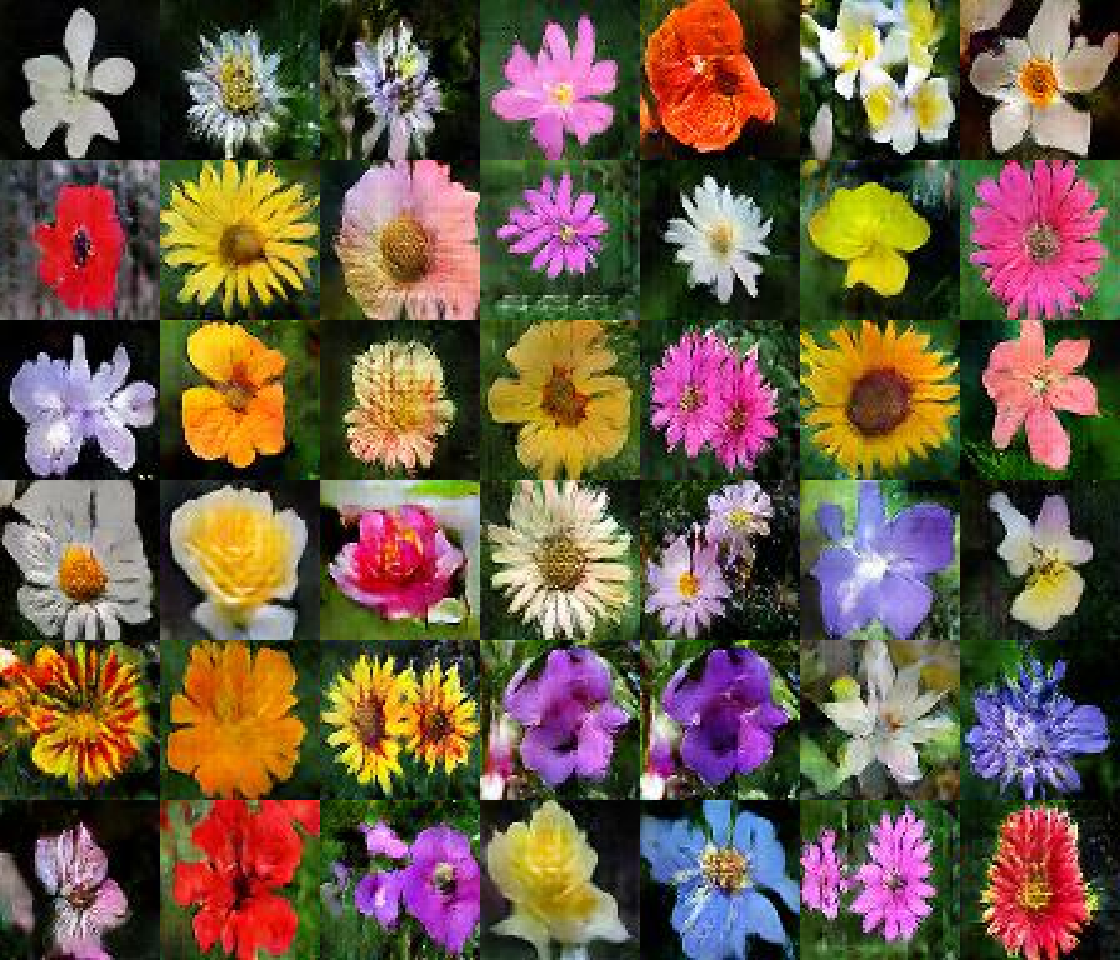

In [37]:
random_idx = [23, 216, 224, 413, 713, 859, 876, 974, 1177, 1179, 1241, 2169, 2196, 2237,
              2356, 2611, 2621, 2786, 2951, 2962, 3145, 3255, 3327, 3639, 3654, 3927, 4262,
              4321, 4517, 5067, 5147, 5955, 6167, 6216, 6410, 6413, 6579, 6584, 6804, 6988,
              7049, 7160]

visualize(random_idx)

Unfortunately, it is not perfect. The following figure illustrates images chosen randomly, without cherry picking.

the flower shown has white petals and bright yellow anthers
this flower has large white petals with purple tips and no visible stigma
this flower is yellow and white in color with petals that are oval shaped
this small flower has several smooth orange petals with round edges
this flower has petals that are orange with white stamen
a flower with wide broad blue petals and central cluster of green stamen
this flower has a very tall pistol and pink petals that have white streaks through them
an orange and red flower with ruffled petals and a long filament shooting out the top
this flower has petals that are red with yellow stigma
this flower is rose like with overlapping pink petals and a green pedicel
the flower has yellow petals overlapping each other and are yellow in color
the flower has yellow petals overlapping each other and are yellow in color
the petals of the flower are red in color and have green leaves
this is a red double flower that has soft petals and yellow stamens in the 

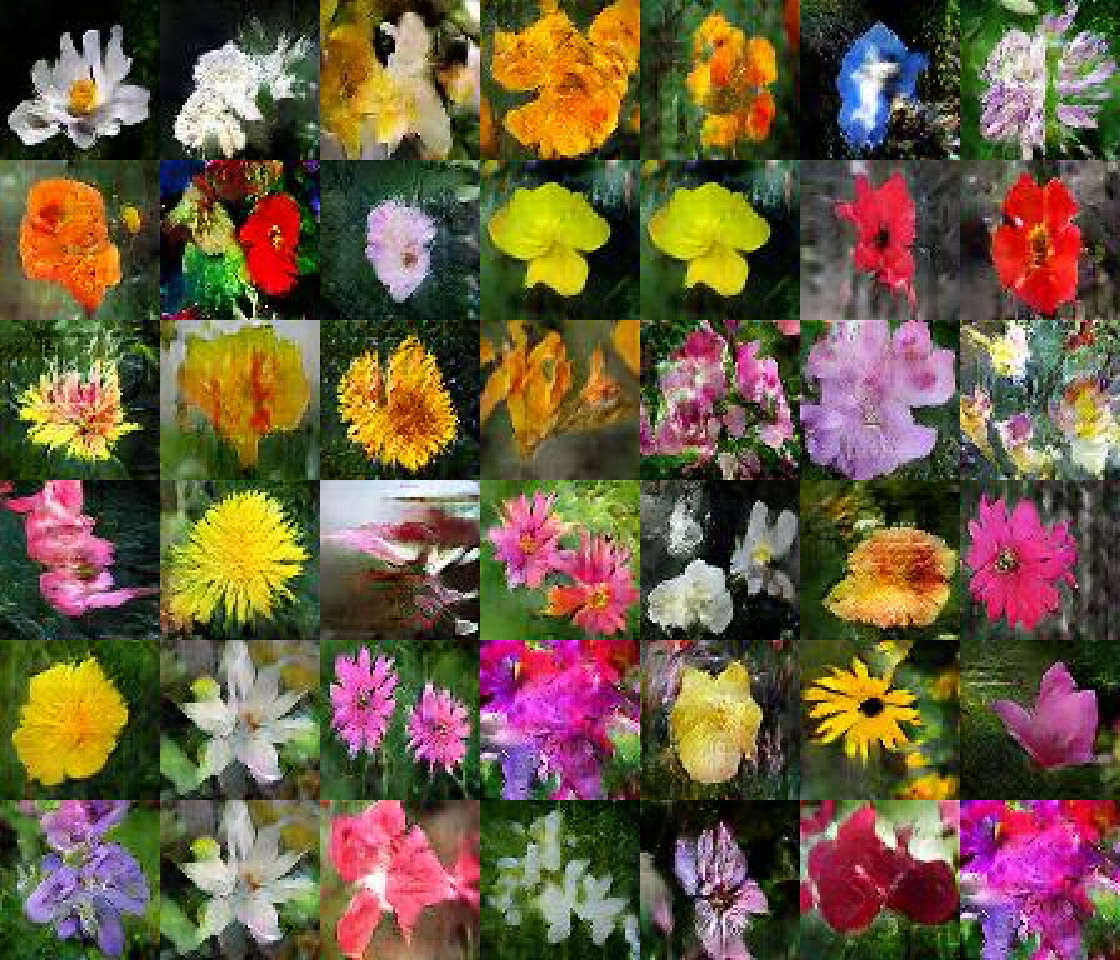

In [38]:
DATA_PATH = TA80_DEMO_DIR
img_path = Path(DATA_PATH).glob('*.jpg')
img_path = [str(path.resolve()) for path in img_path]
img_path = np.asarray(img_path)

idx = np.random.randint(len(img_path), size=42)
idx.sort()

random_idx = []
for each in idx:
    # extract the filename (last path component)
    filename = Path(img_path[each]).name
    # strip 'inference_' and '.jpg' and convert to an int
    num = int(filename.replace('inference_', '').replace('.jpg', ''))
    random_idx.append(num)

visualize(random_idx)